Code to plot spin split Andreev Bound Spectrum E vs phi

In [10]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
#import Minimal_Model_2D as mm2d
import time

np.set_printoptions(threshold=sys.maxsize)

import Minimal_Model_1D as M



In [2]:
import matplotlib.pyplot as plt
print(plt.rcParams['text.usetex'])

False


In [3]:
sys.path

['c:\\Users\\avani\\OneDrive\\Desktop\\Spin_Splitting_Ge_ABS\\Figure_code_final',
 'C:\\Program Files\\WindowsApps\\PythonSoftwareFoundation.Python.3.9_3.9.3568.0_x64__qbz5n2kfra8p0\\python39.zip',
 'C:\\Program Files\\WindowsApps\\PythonSoftwareFoundation.Python.3.9_3.9.3568.0_x64__qbz5n2kfra8p0\\DLLs',
 'C:\\Program Files\\WindowsApps\\PythonSoftwareFoundation.Python.3.9_3.9.3568.0_x64__qbz5n2kfra8p0\\lib',
 'C:\\Users\\avani\\AppData\\Local\\Microsoft\\WindowsApps\\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0',
 '',
 'C:\\Users\\avani\\AppData\\Local\\Packages\\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\\LocalCache\\local-packages\\Python39\\site-packages',
 'C:\\Users\\avani\\AppData\\Local\\Packages\\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\\LocalCache\\local-packages\\Python39\\site-packages\\win32',
 'C:\\Users\\avani\\AppData\\Local\\Packages\\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\\LocalCache\\local-packages\\Python39\\site-packages\\win32\\lib'

In [4]:
NSM = 60          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
LY = 75           # Width in nm
ALPHAT = 20        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 500
N = 2*NSC + NSM



print('first subband energy =' , OMEGA/2 , '\n', 'second subband energy =' , 3*OMEGA/2)

MU_SM = 0.8 + OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.8 + OMEGA/2        ## constant potential over reference level across all widths

print('mu_sc = ',MU_SC , 'mu_sm = ', MU_SM )

PHI = np.linspace(-1.2*np.pi,1.2*np.pi,101)
K = 12

Ep_s = np.empty((PHI.shape[0],K))

D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

for i in range(PHI.shape[0]):

    H = D.H_sys(PHI[i], so='li' )
    
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    
    Ep_s[i,:] =np.sort(E)
    
    if i%10==0:
        print(i)




first subband energy = 1.1789724682017417 
 second subband energy = 3.536917404605225
mu_sc =  1.9789724682017418 mu_sm =  1.9789724682017418
0
10
20
30
40
50
60
70
80
90
100


In [5]:
np.save("abs_vs_phi_for_width_{}_soc_{}_lsm_{}_mu_{}.npy".format(LY, ALPHAT, NSM*AX, round(MU_SM, 2)),Ep_s)

first subband energy = 1.1789724682017417 
 second subband energy = 3.536917404605225
mu_sc =  1.9789724682017418 mu_sm =  1.9789724682017418


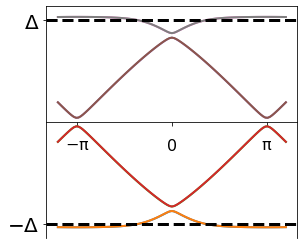

In [6]:
NSM = 60          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
LY = 75           # Width in nm
ALPHAT = 20        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 500
N = 2*NSC + NSM
print('first subband energy =' , OMEGA/2 , '\n', 'second subband energy =' , 3*OMEGA/2)

MU_SM = 0.8 + OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.8 + OMEGA/2        ## constant potential over reference level across all widths

print('mu_sc = ',MU_SC , 'mu_sm = ', MU_SM )

PHI = np.linspace(-1.2*np.pi,1.2*np.pi,101)
K = 12

Ep_s = np.load("abs_vs_phi_for_width_{}_soc_{}_lsm_{}_mu_{}.npy".format(LY, ALPHAT, NSM*AX, round(MU_SM, 2)))
PHI = np.linspace(-1.2*np.pi,1.2*np.pi,101)

# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=16)

f = plt.figure(figsize=(4.5, 4))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

ax = plt.axes()

#Ep2 = Ep[:,2:6]
Ep2_s = Ep_s[:,2:10]

for i in range(Ep2_s.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.plot(PHI/np.pi, Ep2_s[:,i]/DELTA, lw=2)

# Increase the font size of the axes labels and title
#plt.xlabel(r'$\phi/\pi$', fontsize=24)
#plt.ylabel(r'Andreev bound state energy', fontsize=24)
#plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

#plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
#plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Specify ticks on the y-axis 
ax.set_yticks(np.linspace(-1,1,num=2))
ax.set_xticks(np.array([-1, 0, 1]))

# setting label for y tick 
#ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 
ax.set_yticklabels([r'$-\Delta$', r'$\Delta$'], fontsize=20) 
ax.set_xticklabels([r'$\mathrm{-\pi}$',r'$\mathrm{0}$', r'$\mathrm{\pi}$'], fontsize=10) 

# Move the x-axis to the center
ax.spines['bottom'].set_position(('data', 0))  # Move the x-axis to y=0
#ax.spines['top'].set_color('none')  # Hide the top spine


# Add label padding to move the x-tick labels away from the plot
ax.tick_params(axis='x', pad=12)  # Adjust the padding value as needed

# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.show()

In [2]:
NSM = 60          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
LY = 75           # Width in nm
ALPHAT = 20        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 500
N = 2*NSC + NSM



print('first subband energy =' , OMEGA/2 , '\n', 'second subband energy =' , 3*OMEGA/2)

MU_SM = 0.8 + OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.8 + OMEGA/2        ## constant potential over reference level across all widths

print('mu_sc = ',MU_SC , 'mu_sm = ', MU_SM )

PHI = np.linspace(-0.48*np.pi,-0.52*np.pi,101)
K = 12

Ep_s = np.empty((PHI.shape[0],K))

D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

for i in range(PHI.shape[0]):

    H = D.H_sys(PHI[i], so='li' )
    
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    
    Ep_s[i,:] =np.sort(E)
    
    if i%10==0:
        print(i)

np.save("abs_vs_phi_for_width_{}_soc_{}_lsm_{}_mu_{}_zoom_phi_from_{}_to_{}_num_{}.npy".format(LY, ALPHAT, NSM*AX, round(MU_SM, 2), round(PHI[0],2), round(PHI[-1],2), PHI.shape[0]),Ep_s)

first subband energy = 1.1789724682017417 
 second subband energy = 3.536917404605225
mu_sc =  1.9789724682017418 mu_sm =  1.9789724682017418
0
10
20
30
40
50
60
70
80
90
100


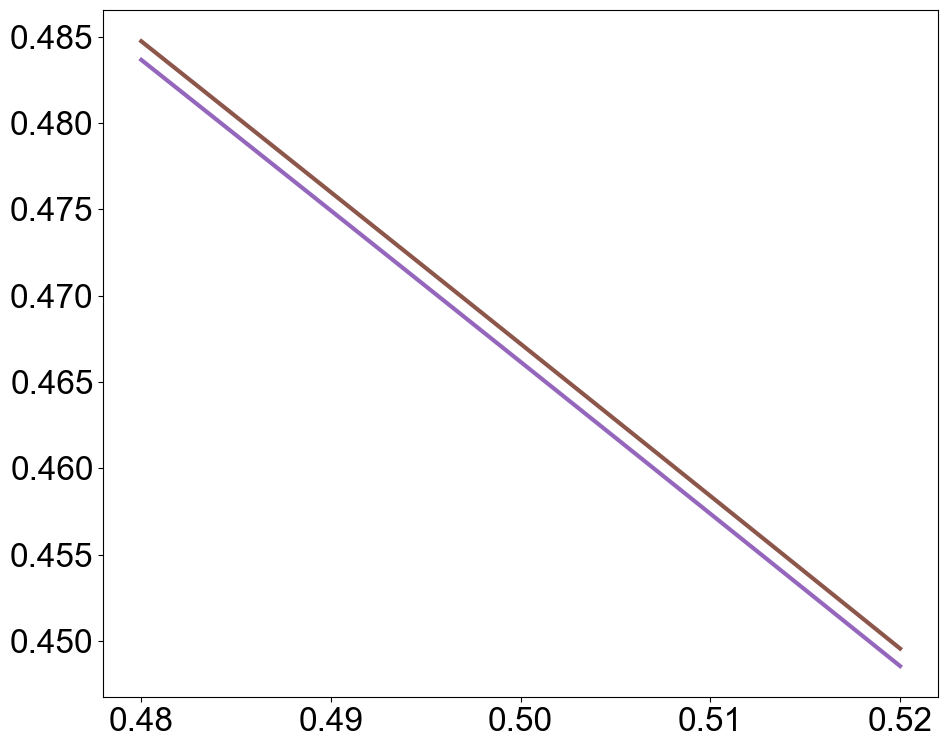

In [12]:

# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

#ax = plt.axes()

#Ep2 = Ep[:,2:6]
Ep2_s = Ep_s[:,6:8]

#PHI = np.linspace(-0.6*np.pi,-0.4*np.pi,101)

# Define your custom color sequence
colors = ['#9467bd', '#8c564b']

for i in range(Ep2_s.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.plot(PHI/np.pi, Ep2_s[:,i]/DELTA, lw=3, color= colors[i])

# Increase the font size of the axes labels and title
#plt.xlabel(r'$\phi/\pi$', fontsize=24)
#plt.ylabel(r'Andreev bound state energy', fontsize=24)
#plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

#plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
#plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Specify ticks on the y-axis 
#ax.set_yticks(np.linspace(-1,1,num=5))

# setting label for y tick 
#ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 


# Add dashed lines at +1 and -1 on the y-axis
#plt.axhline(1, color='black', linestyle='dashed', lw=3)
#plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.show()

In [43]:
NSM = 3          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
LY = 10           # Width in nm
ALPHAT = 0        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 500
N = 2*NSC + NSM



print('first subband energy =' , OMEGA/2 , '\n', 'second subband energy =' , 3*OMEGA/2)

MU_SM = 5 + OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 5 + OMEGA/2        ## constant potential over reference level across all widths

print('mu_sc = ',MU_SC , 'mu_sm = ', MU_SM )

PHI = np.linspace(-1.2*np.pi,1.2*np.pi,101)
K = 12

Ep_s = np.empty((PHI.shape[0],K))

D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

for i in range(PHI.shape[0]):

    H = D.H_sys(PHI[i], so='li' )
    
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    
    Ep_s[i,:] =np.sort(E)
    
    if i%10==0:
        print(i)


np.save("ideal_abs_vs_phi_for_width_{}_soc_{}_lsm_{}_mu_{}_phi_from_{}_to_{}_num_{}.npy".format(LY, ALPHAT, NSM*AX, round(MU_SM, 2), round(PHI[0],2), round(PHI[-1],2), PHI.shape[0]),Ep_s)

first subband energy = 66.31720133634798 
 second subband energy = 198.95160400904393
mu_sc =  71.31720133634798 mu_sm =  71.31720133634798
0
10
20
30
40
50
60
70
80
90
100


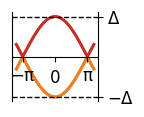

In [68]:
# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=12)

f = plt.figure(figsize=(1.5, 1.5))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

ax = plt.axes()

#Ep2 = Ep[:,2:6]
Ep2_s = Ep_s[:,4:8]

for i in range(Ep2_s.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.plot(PHI/np.pi, Ep2_s[:,i]/DELTA, lw=2, zorder=1)

# Increase the font size of the axes labels and title
#plt.xlabel(r'$\phi/\pi$', fontsize=24)
#plt.ylabel(r'Andreev bound state energy', fontsize=24)
#plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

#plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
#plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Specify ticks on the y-axis 
ax.set_yticks(np.linspace(-1,1,num=2))
ax.set_xticks(np.array([-1, 0, 1]))

# setting label for y tick 
#ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 
ax.set_yticklabels([r'$-\Delta$', r'$\Delta$']) 
ax.set_xticklabels([r'$\mathrm{-\pi}$',r'$\mathrm{0}$', r'$\mathrm{\pi}$']) 

# Move y-tick labels to the right
ax.yaxis.tick_right()
ax.yaxis.set_label_position("right")

# Bring ticks to the front using zorder
ax.tick_params(axis='both', which='both', zorder=4)  # Adjust zorder for ticks

# Move the x-axis to the center
ax.spines['bottom'].set_position(('data', 0))  # Move the x-axis to y=0
#ax.spines['bottom'].set_position()  # Move the x-axis to y=0
#ax.spines['bottom'].set_visible(True)  # Make sure the bottom spine is visible
ax.spines['top'].set_color('none')  # Hide the top spine


# Add label padding to move the x-tick labels away from the plot
ax.tick_params(axis='x', pad=5)  # Adjust the padding value as needed

# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=1)
plt.axhline(-1, color='black', linestyle='dashed', lw=1)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.show()

first subband energy = 1.1789724682017417 
 second subband energy = 3.536917404605225
mu_sc =  1.9789724682017418 mu_sm =  1.9789724682017418


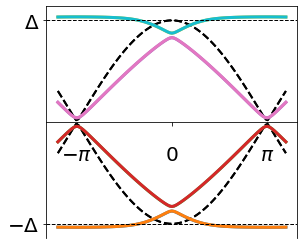

In [7]:
NSM = 60          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
LY = 75           # Width in nm
ALPHAT = 20        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 500
N = 2*NSC + NSM



print('first subband energy =' , OMEGA/2 , '\n', 'second subband energy =' , 3*OMEGA/2)

MU_SM = 0.8 + OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.8 + OMEGA/2        ## constant potential over reference level across all widths

print('mu_sc = ',MU_SC , 'mu_sm = ', MU_SM )

# Custom color cycle, excluding gray
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#e377c2', '#bcbd22', '#17becf']
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=colors)


PHI = np.linspace(-1.2*np.pi,1.2*np.pi,101)
K = 12

Ep_s = np.load("abs_vs_phi_for_width_{}_soc_{}_lsm_{}_mu_{}.npy".format(LY, ALPHAT, NSM*AX, round(MU_SM, 2)))
Ep_s_ideal = np.load("ideal_abs_vs_phi_for_width_10_soc_0_lsm_15_mu_71.32_phi_from_-3.77_to_3.77_num_101.npy")
PHI = np.linspace(-1.2*np.pi,1.2*np.pi,101)

# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

#plt.rc('font', size=16)

f = plt.figure(figsize=(4.5, 4))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

ax = plt.axes()

#Ep2 = Ep[:,2:6]
Ep2_s = Ep_s[:,2:10]

for i in range(Ep2_s.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.plot(PHI/np.pi, Ep2_s[:,i]/DELTA, lw=3)


#Ep2 = Ep[:,2:6]
Ep2_s_ideal = Ep_s_ideal[:,4:8]

for i in range(Ep2_s_ideal.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.plot(PHI/np.pi, Ep2_s_ideal[:,i]/DELTA, lw=2, zorder=1, linestyle='dashed', color="black")

# Increase the font size of the axes labels and title
#plt.xlabel(r'$\phi/\pi$', fontsize=24)
#plt.ylabel(r'Andreev bound state energy', fontsize=24)
#plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

#plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
#plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Specify ticks on the y-axis 
ax.set_yticks(np.linspace(-1,1,num=2))
ax.set_xticks(np.array([-1, 0, 1]))

# setting label for y tick 
#ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 
ax.set_yticklabels([r'$-\Delta$', r'$\Delta$'], fontsize=20) 
ax.set_xticklabels([r'$-\pi$',r'$0$', r'$\pi$']) 

# Move the x-axis to the center
ax.spines['bottom'].set_position(('data', 0))  # Move the x-axis to y=0
#ax.spines['top'].set_color('none')  # Hide the top spine


# Add label padding to move the x-tick labels away from the plot
ax.tick_params(axis='x', pad=20, labelsize=20)  # Adjust the padding value as needed

# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=1)
plt.axhline(-1, color='black', linestyle='dashed', lw=1)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.show()

first subband energy = 1.1789724682017417 
 second subband energy = 3.536917404605225
mu_sc =  1.9789724682017418 mu_sm =  1.9789724682017418


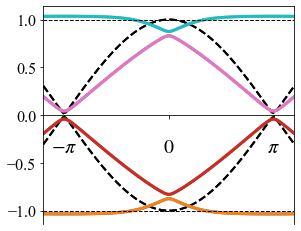

In [8]:
# Update rcParams for Times New Roman-like font
plt.rcParams.update({
    "font.family": "serif",         # Use serif font family
    "font.serif": ["Times New Roman"],  # Specify Times New Roman explicitly
    "mathtext.fontset": "stix",     # Use STIX fonts for math (similar to Times)
    "mathtext.rm": "Times New Roman",   # Roman font for math text
    "mathtext.it": "Times New Roman:italic",  # Italic font for math
    "mathtext.bf": "Times New Roman:bold",    # Bold font for math
#    "axes.labelsize": 12,            # Font size for axes labels
#    "xtick.labelsize": 10,           # Font size for x-tick labels
#    "ytick.labelsize": 10,           # Font size for y-tick labels
#    "legend.fontsize": 10,           # Font size for legends
#    "figure.titlesize": 14           # Font size for figure title
})

NSM = 60          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
LY = 75           # Width in nm
ALPHAT = 20        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 500
N = 2*NSC + NSM



print('first subband energy =' , OMEGA/2 , '\n', 'second subband energy =' , 3*OMEGA/2)

MU_SM = 0.8 + OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.8 + OMEGA/2        ## constant potential over reference level across all widths

print('mu_sc = ',MU_SC , 'mu_sm = ', MU_SM )

# Custom color cycle, excluding gray
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#e377c2', '#bcbd22', '#17becf']
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=colors)


PHI = np.linspace(-1.2*np.pi,1.2*np.pi,101)
K = 12

Ep_s = np.load("abs_vs_phi_for_width_{}_soc_{}_lsm_{}_mu_{}.npy".format(LY, ALPHAT, NSM*AX, round(MU_SM, 2)))
Ep_s_ideal = np.load("ideal_abs_vs_phi_for_width_10_soc_0_lsm_15_mu_71.32_phi_from_-3.77_to_3.77_num_101.npy")
PHI = np.linspace(-1.2*np.pi,1.2*np.pi,101)

# Set the font family to Arial
#plt.rcParams['font.family'] = 'Arial'

#plt.rc('font', size=16)

f = plt.figure(figsize=(4.5, 4))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

ax = plt.axes()

#Ep2 = Ep[:,2:6]
Ep2_s = Ep_s[:,2:10]

for i in range(Ep2_s.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.plot(PHI/np.pi, Ep2_s[:,i]/DELTA, lw=3)


#Ep2 = Ep[:,2:6]
Ep2_s_ideal = Ep_s_ideal[:,4:8]

for i in range(Ep2_s_ideal.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.plot(PHI/np.pi, Ep2_s_ideal[:,i]/DELTA, lw=2, zorder=1, linestyle='dashed', color="black")

# Increase the font size of the axes labels and title
#plt.xlabel(r'$\phi/\pi$', fontsize=24)
#plt.ylabel(r'Andreev bound state energy', fontsize=24)
#plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

#plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
#plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

#plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Specify ticks on the y-axis 
#ax.set_yticks(np.linspace(-1,1,num=2))
ax.set_xticks(np.array([-1, 0, 1]))

# setting label for y tick 
#ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 
#ax.set_yticklabels([r'$-\Delta$', r'$\Delta$'], fontsize=20) 
ax.set_xticklabels([r'$-\pi$',r'$0$', r'$\pi$']) 

# Move the x-axis to the center
ax.spines['bottom'].set_position(('data', 0))  # Move the x-axis to y=0
#ax.spines['top'].set_color('none')  # Hide the top spine


# Add label padding to move the x-tick labels away from the plot
ax.tick_params(axis='x', pad=20, labelsize=20)  # Adjust the padding value as needed

# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=1)
plt.axhline(-1, color='black', linestyle='dashed', lw=1)

plt.xlim(xmin=-1.2, xmax=1.2)
# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))
plt.savefig('Andreev_bound_spectrum.png', dpi=300, bbox_inches='tight')

plt.show()

first subband energy = 1.1789724682017417 
 second subband energy = 3.536917404605225
mu_sc = 1.9789724682017418 mu_sm = 1.9789724682017418


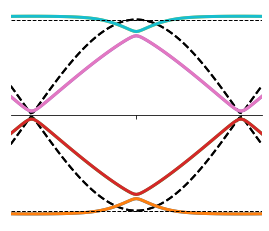

In [14]:
# Update rcParams for Times New Roman-like font
plt.rcParams.update({
    "font.family": "serif",         # Use serif font family
    "font.serif": ["Times New Roman"],  # Specify Times New Roman explicitly
    "mathtext.fontset": "stix",     # Use STIX fonts for math (similar to Times)
    "mathtext.rm": "Times New Roman",   # Roman font for math text
    "mathtext.it": "Times New Roman:italic",  # Italic font for math
    "mathtext.bf": "Times New Roman:bold",    # Bold font for math
})

# Constants
NSM = 60          # in nm
MY = 7            # no of subbands
AX = 5            # lattice spacing in nm
LY = 75           # Width in nm
ALPHAT = 20       # meV-nm
DELTA = 0.165     # in meV
MEFF_SC = 0.023   # proximitized Ge 
MEFF_SM = 0.023   # Ge
OMEGA = 2 * 4 * hbm / LY**2 / MEFF_SC
NSC = 500
N = 2 * NSC + NSM

print('first subband energy =', OMEGA / 2, '\n', 'second subband energy =', 3 * OMEGA / 2)

MU_SM = 0.8 + OMEGA / 2  # Chemical potential for semiconductor
MU_SC = 0.8 + OMEGA / 2  # Chemical potential for superconductor

print('mu_sc =', MU_SC, 'mu_sm =', MU_SM)

# Custom color cycle, excluding gray
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#e377c2', '#bcbd22', '#17becf']
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=colors)

PHI = np.linspace(-1.2 * np.pi, 1.2 * np.pi, 101)

# Load data
Ep_s = np.load("abs_vs_phi_for_width_{}_soc_{}_lsm_{}_mu_{}.npy".format(LY, ALPHAT, NSM * AX, round(MU_SM, 2)))
Ep_s_ideal = np.load("ideal_abs_vs_phi_for_width_10_soc_0_lsm_15_mu_71.32_phi_from_-3.77_to_3.77_num_101.npy")

# Plot setup
f = plt.figure(figsize=(4.5, 4))
ax = plt.axes()

# Plot Ep_s data
Ep2_s = Ep_s[:, 2:10]
for i in range(Ep2_s.shape[1]):
    plt.plot(PHI / np.pi, Ep2_s[:, i] / DELTA, lw=3)

# Plot Ep_s_ideal data
Ep2_s_ideal = Ep_s_ideal[:, 4:8]
for i in range(Ep2_s_ideal.shape[1]):
    plt.plot(PHI / np.pi, Ep2_s_ideal[:, i] / DELTA, lw=2, zorder=1, linestyle='dashed', color="black")

# Remove y-ticks and labels
ax.set_yticks([])  # Removes y-ticks
ax.set_yticklabels([])  # Removes y-tick labels

# Remove y-ticks and labels
ax.set_xticks(np.array([-1, 0, 1]))
ax.set_xticklabels([])  # Removes x-tick labels


# Remove borders (spines)
ax.spines['left'].set_color('none')  # Hide the left spine
ax.spines['right'].set_color('none')  # Hide the right spine
ax.spines['top'].set_color('none')  # Hide the top spine
ax.spines['bottom'].set_color('black')  # Keep the bottom spine for x-axis

# Set x-tick labels
#ax.set_xticks(np.array([-1, 0, 1]))
#ax.set_xticklabels([r'$-\pi$', r'$0$', r'$\pi$'])

# Move the x-axis to the center
ax.spines['bottom'].set_position(('data', 0))  # Move the x-axis to y=0

# Add label padding to move the x-tick labels away from the plot
ax.tick_params(axis='x', pad=20, labelsize=20)

# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=1)
plt.axhline(-1, color='black', linestyle='dashed', lw=1)

# Set x-axis limits
plt.xlim(xmin=-1.2, xmax=1.2)

# Save the plot as an image file
plt.savefig('Andreev_bound_spectrum.png', dpi=300, bbox_inches='tight')

plt.show()


In [3]:
PHI = np.linspace(-0.48*np.pi,-0.52*np.pi,101)

Ep_s = np.load("abs_vs_phi_for_width_{}_soc_{}_lsm_{}_mu_{}_zoom_phi_from_{}_to_{}_num_{}.npy".format(LY, ALPHAT, NSM*AX, round(MU_SM, 2), round(PHI[0],2), round(PHI[-1],2), PHI.shape[0]))

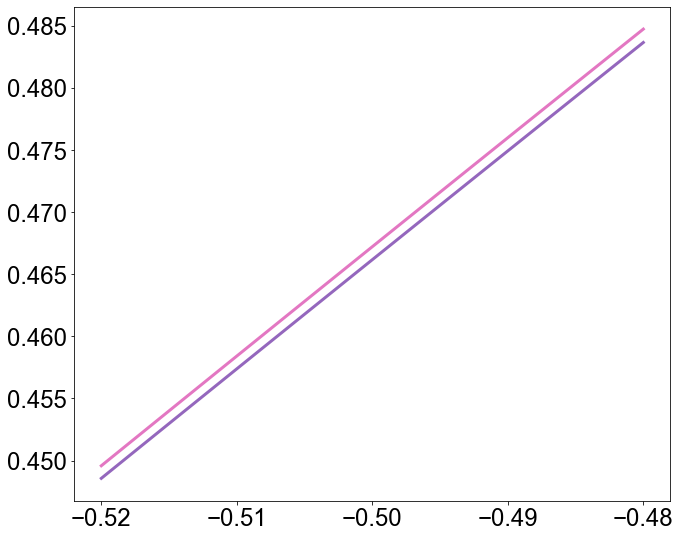

In [4]:

# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

# Custom color cycle, excluding gray
colors = [ '#9467bd', '#e377c2']
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=colors)

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

#ax = plt.axes()

#Ep2 = Ep[:,2:6]
Ep2_s = Ep_s[:,6:8]

#PHI = np.linspace(-0.6*np.pi,-0.4*np.pi,101)


for i in range(Ep2_s.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.plot(PHI/np.pi, Ep2_s[:,i]/DELTA, lw=3, color= colors[i])

# Increase the font size of the axes labels and title
#plt.xlabel(r'$\phi/\pi$', fontsize=24)
#plt.ylabel(r'Andreev bound state energy', fontsize=24)
#plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

#plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
#plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Specify ticks on the y-axis 
#ax.set_yticks(np.linspace(-1,1,num=5))

# setting label for y tick 
#ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 


# Add dashed lines at +1 and -1 on the y-axis
#plt.axhline(1, color='black', linestyle='dashed', lw=3)
#plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.show()